In [2]:
!pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB 487.6 kB/s eta 0:01:41
   ---------------------------------------- 0.1/48.9 MB 930.9 kB/s eta 0:00:53
   ---------------------------------------- 0.3/48.9 MB 1.6 MB/s eta 0:00:32
   ---------------------------------------- 0.3/48.9 MB 1.6 MB/s eta 0:00:31
   ---------------------------------------- 0.4/48.9 MB 1.6 MB/s eta 0:00:31
   ---------------------------------------- 0.5/48.9 MB 1.7 MB/s eta 0:00:29
   ---------------------------------------- 0.6/48.9 MB 1.6 MB/s eta 0:00:31
    --------------------------------------- 0.7/48.9 MB 1.7 MB/s eta 0:00:29
    --------------------------------------- 0.8/48.9 MB 1.8 MB/s eta 0:00:28
    --------------------------------------- 0.9/48.9 MB 1.9 MB/s eta 0:00:26
    --------------------------------------- 1.0/48.9 MB 1.8 MB/s eta 0:00:26
    -----


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier

In [3]:
df = pd.read_csv("archive/Iris.csv")

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
print("Shape:", df.shape)
print(df.columns)

Shape: (150, 6)
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')


In [5]:
X = df.drop(['Id', 'Species'], axis=1)
y = df['Species']

In [6]:
encoder = LabelEncoder()

y = encoder.fit_transform(y)

print("Classes:", encoder.classes_)

Classes: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [8]:
ada_model = AdaBoostClassifier(
    n_estimators=50,
    random_state=42
)

ada_model.fit(X_train, y_train)

y_pred_ada = ada_model.predict(X_test)

print("AdaBoost Accuracy:",
      accuracy_score(y_test, y_pred_ada))

AdaBoost Accuracy: 0.9333333333333333


In [9]:
gbm_model = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42
)

gbm_model.fit(X_train, y_train)

y_pred_gbm = gbm_model.predict(X_test)

print("Gradient Boosting Accuracy:",
      accuracy_score(y_test, y_pred_gbm))

Gradient Boosting Accuracy: 0.9666666666666667


In [10]:
xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric='mlogloss'
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost Accuracy:",
      accuracy_score(y_test, y_pred_xgb))

XGBoost Accuracy: 0.9333333333333333


In [11]:
hard_voting = VotingClassifier(
    estimators=[
        ('ada', ada_model),
        ('gbm', gbm_model),
        ('xgb', xgb_model)
    ],
    voting='hard'
)

hard_voting.fit(X_train, y_train)

y_pred_hard = hard_voting.predict(X_test)

print("Hard Voting Accuracy:",
      accuracy_score(y_test, y_pred_hard))

Hard Voting Accuracy: 0.9666666666666667


In [12]:
soft_voting = VotingClassifier(
    estimators=[
        ('ada', ada_model),
        ('gbm', gbm_model),
        ('xgb', xgb_model)
    ],
    voting='soft'
)

soft_voting.fit(X_train, y_train)

y_pred_soft = soft_voting.predict(X_test)

print("Soft Voting Accuracy:",
      accuracy_score(y_test, y_pred_soft))

Soft Voting Accuracy: 0.9666666666666667


In [13]:
models = {
    'AdaBoost': y_pred_ada,
    'Gradient Boosting': y_pred_gbm,
    'XGBoost': y_pred_xgb,
    'Hard Voting': y_pred_hard,
    'Soft Voting': y_pred_soft
}

results = []

for name, predictions in models.items():
    
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test,
        predictions,
        average='weighted'
    )
    recall = recall_score(
        y_test,
        predictions,
        average='weighted'
    )
    f1 = f1_score(
        y_test,
        predictions,
        average='weighted'
    )
    
    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        'Model',
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score'
    ]
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,AdaBoost,0.933333,0.933333,0.933333,0.933333
1,Gradient Boosting,0.966667,0.969697,0.966667,0.966583
2,XGBoost,0.933333,0.933333,0.933333,0.933333
3,Hard Voting,0.966667,0.969697,0.966667,0.966583
4,Soft Voting,0.966667,0.969697,0.966667,0.966583


In [14]:
results_df[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
] = results_df[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
] * 100

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,AdaBoost,93.333333,93.333333,93.333333,93.333333
1,Gradient Boosting,96.666667,96.969697,96.666667,96.658312
2,XGBoost,93.333333,93.333333,93.333333,93.333333
3,Hard Voting,96.666667,96.969697,96.666667,96.658312
4,Soft Voting,96.666667,96.969697,96.666667,96.658312


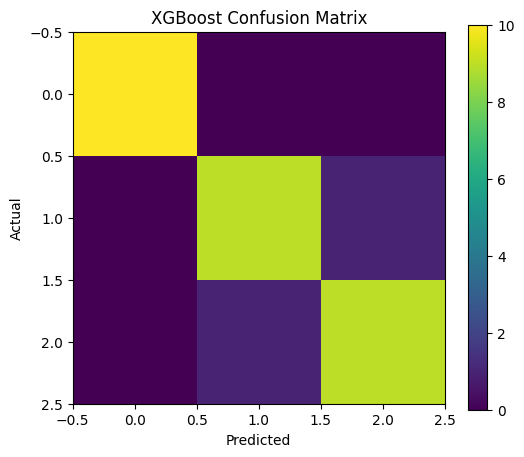

In [15]:
cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.colorbar()

plt.show()

In [16]:
print("AdaBoost")
print(classification_report(
    y_test,
    y_pred_ada,
    target_names=encoder.classes_
))

print("Gradient Boosting")
print(classification_report(
    y_test,
    y_pred_gbm,
    target_names=encoder.classes_
))

print("XGBoost")
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=encoder.classes_
))

AdaBoost
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30

Gradient Boosting
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30

XGBoost
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90